Exercise 1 - Visual assessment

Consider the Cork Stoppers data set. Examine the box/violin plots for each
feature and examine their discriminative power (see Figure 1 as an example for
the RAN feature).

In [ ]:
import pandas as pd 
import plotly.express as px
folder = "D:/UC_library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets/"

df = pd.read_excel(folder + "CORK_STOPPERS.XLS", sheet_name="Data")
df = df.dropna()
df.describe()

features = ["ART", "N.1", "PRT", "ARM", "PRM", "ARTG", "NG", "PRTG", "RAAR", "RAN"]
quality = ["Super", "Average", "Poor"]

df["C"] = df["C"].map({1:quality[0], 2:quality[1], 3:quality[2]})

for i in features:
    px.violin(data_frame=df, x="C", y=i, color="C", labels={"C":"Quality"}, box=True, points='all' ).show()
    # violin - box=TRue displays boxplot inside violin,  point='all' displays all the poins beside


Exercise 2 - Kruskal Wallis Test

The Kruskal Wallis test assesses whether N samples belonging to K classes are
from the same population (or from populations with continuous distribution)
and have the same median for the variable being tested.

Consider again the Cork Stoppers data set.
1. Use SciPy stats.kruskal function to evaluate the discriminative power
of each feature. Rank features according to H.

In [ ]:
from scipy import stats
import numpy as np

H = {feature : None for feature in features}

for i in features:
    Super = df.loc[df["C"] == "Super", i].values
    Average = df.loc[df["C"] == "Average", i].values
    Poor = df.loc[df["C"] == "Poor", i].values

    H[i] =  stats.kruskal(Super, Average, Poor).statistic
   
sort_H = sorted(H.items(), key= lambda x:x[1], reverse=True)

for key,value in sort_H:
    print(key , ':' , value)


2. Find the Correlation Matrix for the 5 first features of the data set.
Inspect about redundancy.

In [ ]:
df1 = df[features[0:5]] # first 5 features of dataset
corr = df1.corr() # correlation matrix 
px.imshow(
    corr,
    text_auto=True,
    title="Correlation matrix for first 5 features",
    color_continuous_scale="RdBu_r",
    aspect="auto"
).show()  

By analysing the correlation matrix we can see that there is a strong correlation between these pairs:
 - ART : PRT;
 - ARM : PRM;

Exercise 3 - ROC Curves
1. The Excel file SignalNoise.xls, contains 100 samples of signal + noise.
The arrival times of the signal impulses have a Poisson distribution. Change
the value of the detection threshold and observe the changes performed
on the detections. Construct a ROC curve.

In [ ]:
# from openpyxl import load_workbook
import pandas as pd
import win32com.client as win32
import plotly.express as px

folder = "D:/UC.library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets/"

excel = win32.Dispatch("Excel.Application")
excel.Visible = False  # Excel runs in background

df2  = pd.read_excel(folder + "SIGNAL_NOISE.xlsx", sheet_name="Data", header=None, names=["signal", "label"])
threshold = [0.8, 1, 2, 3, 4, 5, 6, 7]

wb = excel.Workbooks.Open(folder + "SIGNAL_NOISE.xlsx")
ws = wb.worksheets("Signal+noise")

# dictionary -> sensibility : specificity
D = {}

# change the threshold values 
for value in threshold:
  
    ws.Range("I3").Value = value
    excel.Calculate()
    wb.Save()

    df3 = pd.read_excel(folder + "SIGNAL_NOISE.xlsx", sheet_name="Signal+noise")
    D[ws.Range("L104").Value] =  1 - ws.Range("M104").Value   # eache sensib value corresponds to a specif value


wb.Close()
excel.Quit()

ROC = pd.DataFrame(list(D.items()), columns=["sensib", "specif"])
print(ROC)


px.line(ROC, x = "specif", y = "sensib", title="ROC Curve", labels={"specif" : "1 - SP", "sensib" : "SS"}).show()


2. Consider the Cork Stoppers Data Set first two classes. Use the ROC
curve approach to rank the features. Rank the features and compare it
with the raking by performed by Kruskal-Wallis.

In [13]:
## for each feature compute various threshold values for 2 classess. Claculate the TP, TN, FP, FN and correspondig 1 - specificity (SP) and 
# sensibility (SS) for each threshold value and calculate the AUC from the ROC curve obtained by 1 - SP over SS
import pandas as pd
import plotly.express as px


folder = "D:/UC.library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets/"

Corck = pd.read_excel(folder + "CORK_STOPPERS.XLS", sheet_name="Data")
# Corck.dropna()
Corck = Corck[Corck["C"].isin([1, 2])]
Corck.describe()


# Super = df.loc[df["C"] == "Super", i].values

# arm1 = Corck.loc[Corck["C"] == "1", "ARM"].values
# arm2 = Corck.loc[Corck["C"] == "2", "ARM"].values
# c = Corck.loc[Corck["C"] != "3", "C"].values

for x in features:
    px.scatter(Corck, x = x, y = np.zeros(np.shape(Corck)[0]), color = "C").show()





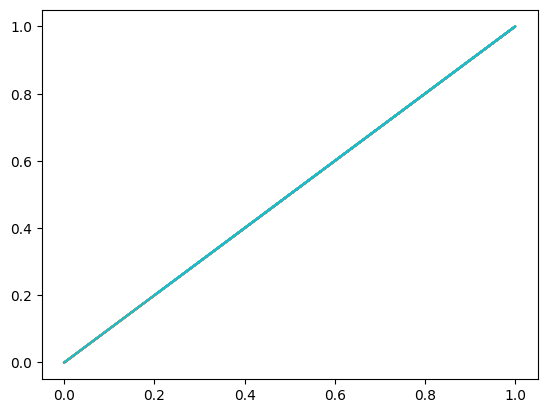

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

predictions = {key: None for key in features}
TP = TN = FP = FN = 0
SS = FPR = []

for feature in features:
    for value in np.linspace(Corck[feature].min(), Corck[feature].max(), 100):

        # make predictions for a colum
        predictions[feature] = (Corck[feature] < value).map({True: 1, False: 2})

        # iterate over indexes
        for i in Corck.index:
            pred = predictions[feature][i]
            real = Corck["C"][i]

            if pred == 1 and real == 1:
                TP += 1
            elif pred == 2 and real == 2:
                TN += 1
            elif pred == 2 and real == 1:
                FN += 1
            else:
                FP += 1

        SS.append(TP / (TP + FN))
        FPR.append(FN / (FP + TN))
    plt.plot(FPR, SS)
    